# Task 4 Trend Prediction Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_path = r"D:\Desktop\Ausify Technologies Internship\Task 1 Data Cleaning\Output\netflix_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (8790, 12)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


In [3]:
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

print("\nRelease year range:")
print(df['release_year'].min(), "-", df['release_year'].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   show_id         8790 non-null   object
 1   type            8790 non-null   object
 2   title           8790 non-null   object
 3   director        8790 non-null   object
 4   country         8790 non-null   object
 5   date_added      8790 non-null   object
 6   release_year    8790 non-null   int64 
 7   rating          8790 non-null   object
 8   duration        8790 non-null   object
 9   listed_in       8790 non-null   object
 10  duration_value  8790 non-null   int64 
 11  duration_unit   8790 non-null   object
dtypes: int64(2), object(10)
memory usage: 824.2+ KB
None

Missing values:
show_id           0
type              0
title             0
director          0
country           0
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
du

In [4]:
yearly_trends = (
    df.groupby('release_year')
    .size()
    .reset_index(name='total_titles')
)

yearly_trends = yearly_trends.sort_values('release_year')

print("Yearly trend data:")
display(yearly_trends.head(10))

print("\nLatest 10 years:")
display(yearly_trends.tail(10))

Yearly trend data:


,release_year,total_titles
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
5,1946,2
6,1947,1
7,1954,2
8,1955,3
9,1956,2



Latest 10 years:


,release_year,total_titles
64,2012,236
65,2013,286
66,2014,352
67,2015,555
68,2016,901
69,2017,1030
70,2018,1146
71,2019,1030
72,2020,953
73,2021,592


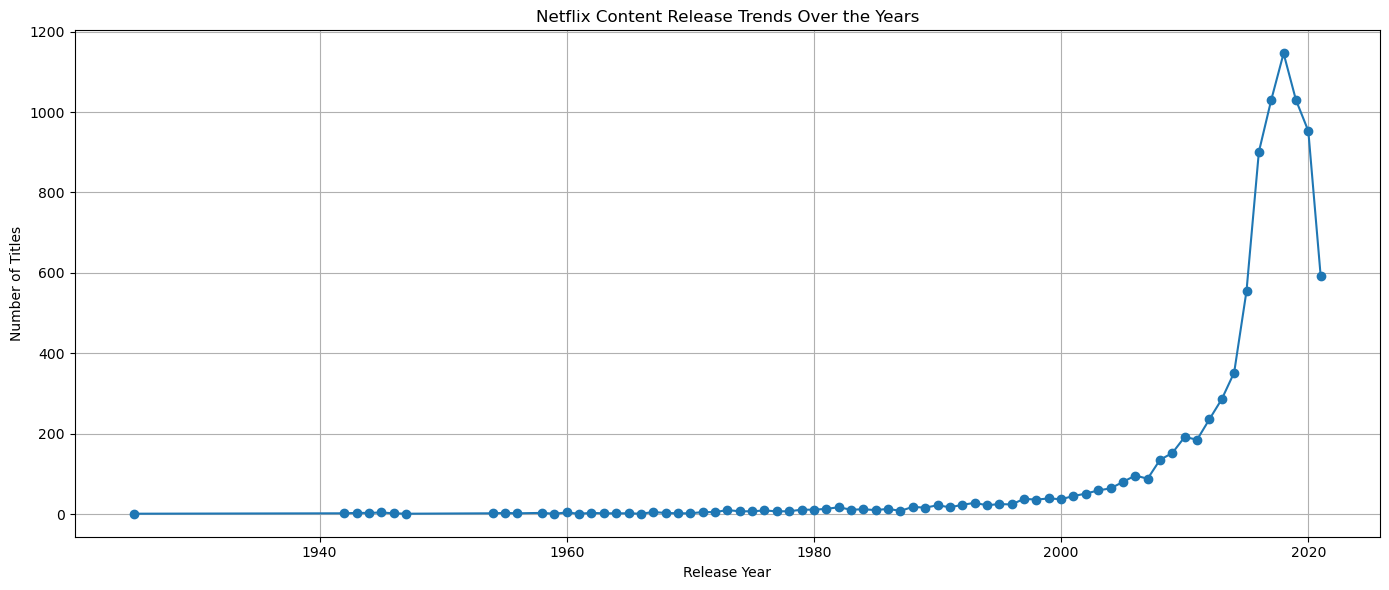

In [5]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_trends['release_year'],
    yearly_trends['total_titles'],
    marker='o'
)

plt.title('Netflix Content Release Trends Over the Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:
# Filter data from 2000 onwards
trend_data = yearly_trends[
    yearly_trends['release_year'] >= 2000
].copy()

# Create a continuous year range
all_years = pd.DataFrame({
    'release_year': range(2000, 2022)
})

# Merge and fill missing years with zero
trend_data = all_years.merge(
    trend_data,
    on='release_year',
    how='left'
)

trend_data['total_titles'] = (
    trend_data['total_titles'].fillna(0).astype(int)
)

display(trend_data)

,release_year,total_titles
0,2000,37
1,2001,45
2,2002,51
3,2003,59
4,2004,64
5,2005,80
6,2006,96
7,2007,88
8,2008,135
9,2009,152


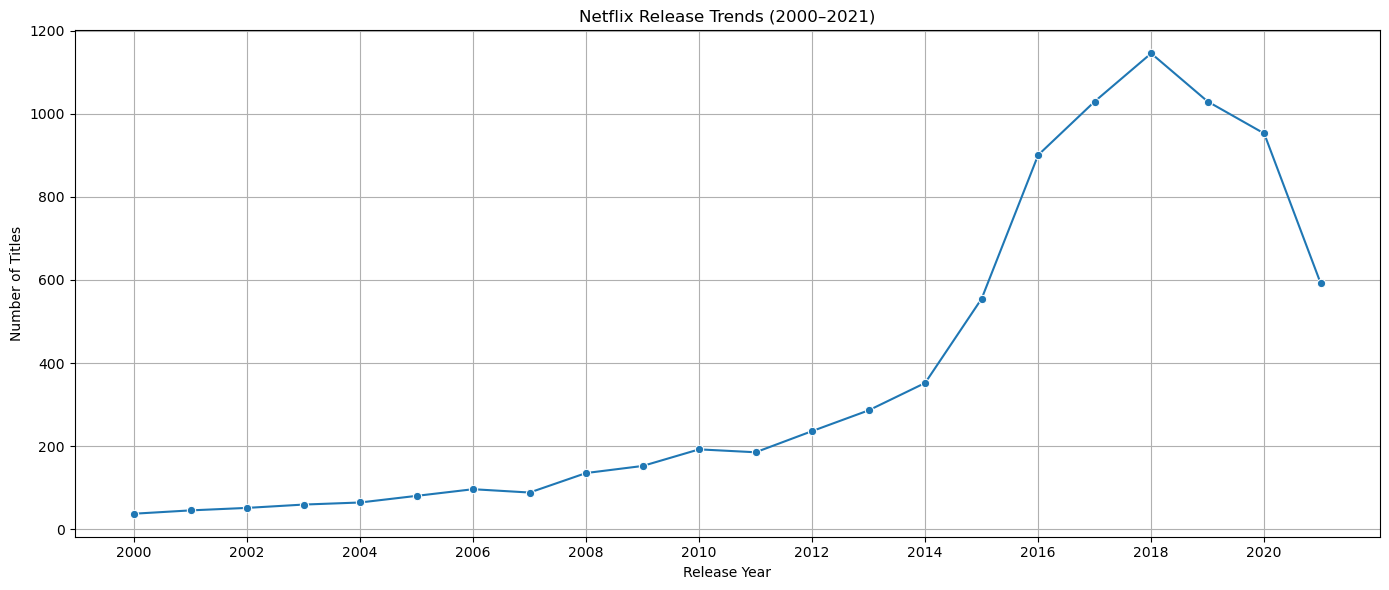

In [7]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=trend_data,
    x='release_year',
    y='total_titles',
    marker='o'
)

plt.title('Netflix Release Trends (2000–2021)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.xticks(range(2000, 2022, 2))
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
# Split data chronologically
train_data = trend_data[trend_data['release_year'] <= 2017]
test_data = trend_data[trend_data['release_year'] >= 2018]

# Independent variable (Year)
X_train = train_data[['release_year']]
X_test = test_data[['release_year']]

# Dependent variable (Number of titles)
y_train = train_data['total_titles']
y_test = test_data['total_titles']

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (18, 1)
Testing data: (4, 1)


In [9]:
# Create Linear Regression model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")
print("Model Coefficient:", model.coef_[0])
print("Model Intercept:", model.intercept_)

Linear Regression Model trained successfully!
Model Coefficient: 44.74716202270382
Model Intercept: -89622.23047815618


In [10]:
# Predict values for test years
y_pred = model.predict(X_test)

# Compare actual and predicted values
comparison = pd.DataFrame({
    'Year': X_test['release_year'].values,
    'Actual Titles': y_test.values,
    'Predicted Titles': np.round(y_pred).astype(int)
})

display(comparison)

,Year,Actual Titles,Predicted Titles
0,2018,1146,678
1,2019,1030,722
2,2020,953,767
3,2021,592,812


In [11]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

Model Evaluation Results
------------------------
MAE: 295.48
MSE: 99256.35
RMSE: 315.05


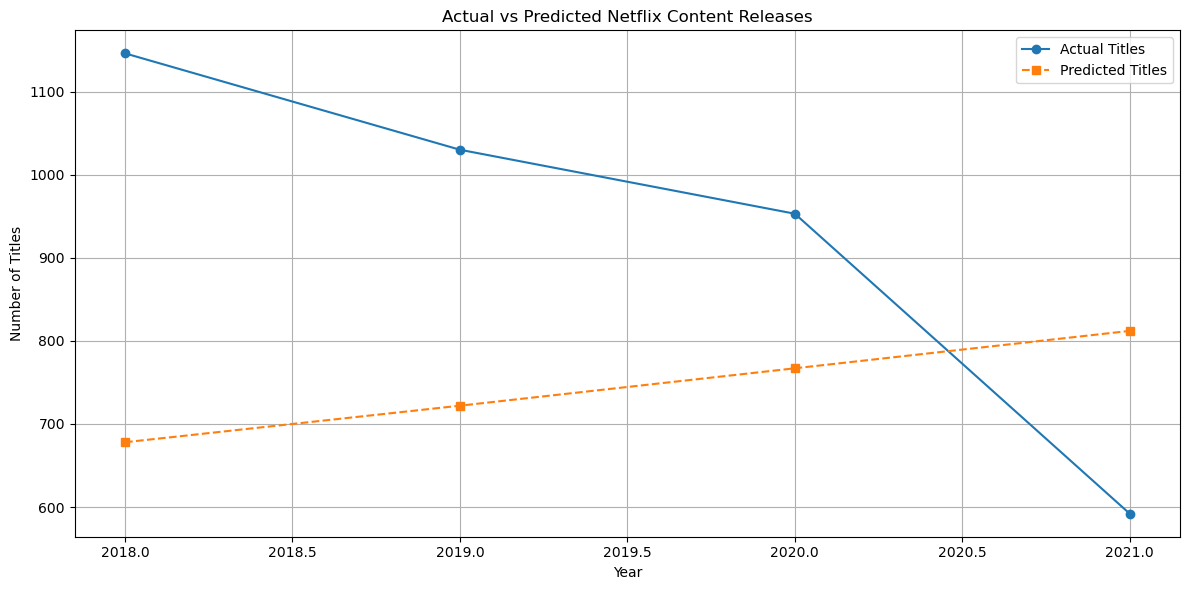

In [12]:
plt.figure(figsize=(12, 6))

plt.plot(
    comparison['Year'],
    comparison['Actual Titles'],
    marker='o',
    label='Actual Titles'
)

plt.plot(
    comparison['Year'],
    comparison['Predicted Titles'],
    marker='s',
    linestyle='--',
    label='Predicted Titles'
)

plt.title('Actual vs Predicted Netflix Content Releases')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Create Polynomial Regression model (degree 2)
poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

# Train model
poly_model.fit(X_train, y_train)

print("Polynomial Regression model trained successfully!")

Polynomial Regression model trained successfully!


In [14]:
# Predict test data
poly_pred = poly_model.predict(X_test)

poly_comparison = pd.DataFrame({
    'Year': X_test['release_year'].values,
    'Actual Titles': y_test.values,
    'Predicted Titles': np.round(poly_pred).astype(int)
})

display(poly_comparison)

,Year,Actual Titles,Predicted Titles
0,2018,1146,679
1,2019,1030,724
2,2020,953,769
3,2021,592,814


In [15]:
poly_mae = mean_absolute_error(y_test, poly_pred)
poly_mse = mean_squared_error(y_test, poly_pred)
poly_rmse = np.sqrt(poly_mse)

print("Polynomial Regression Evaluation")
print("--------------------------------")
print("MAE:", round(poly_mae, 2))
print("MSE:", round(poly_mse, 2))
print("RMSE:", round(poly_rmse, 2))

Polynomial Regression Evaluation
--------------------------------
MAE: 294.99
MSE: 98891.57
RMSE: 314.47


In [16]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression'],
    'MAE': [mae, poly_mae],
    'MSE': [mse, poly_mse],
    'RMSE': [rmse, poly_rmse]
})

display(model_comparison)

,Model,MAE,MSE,RMSE
0,Linear Regression,295.478758,99256.352252,315.049762
1,Polynomial Regression,294.992111,98891.572265,314.470304


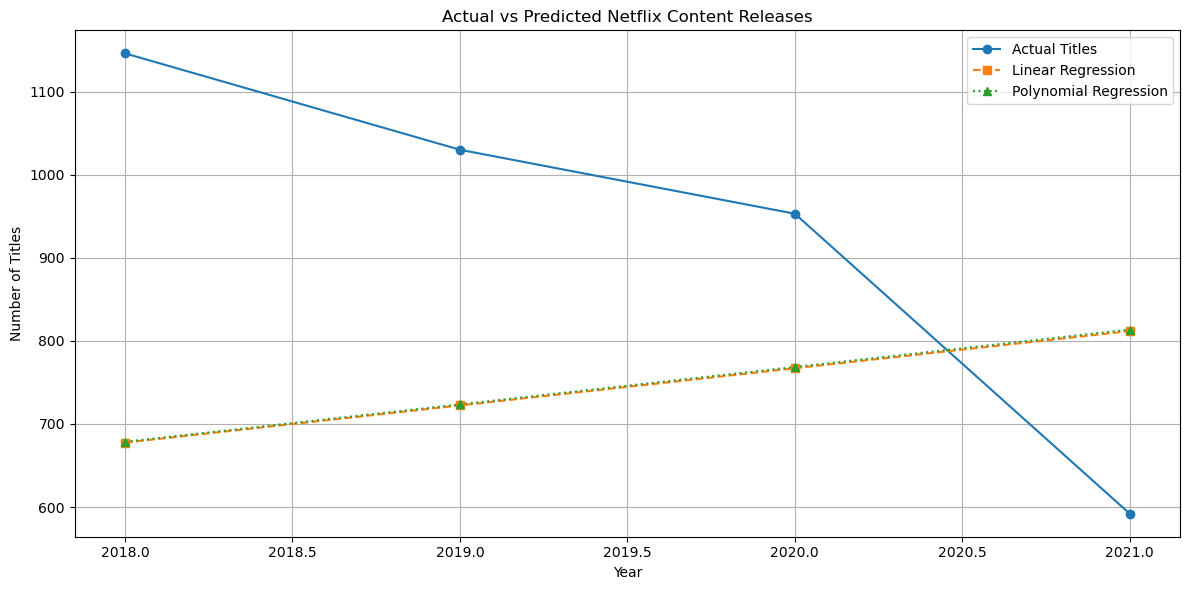

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    X_test['release_year'],
    y_test,
    marker='o',
    label='Actual Titles'
)

plt.plot(
    X_test['release_year'],
    y_pred,
    marker='s',
    linestyle='--',
    label='Linear Regression'
)

plt.plot(
    X_test['release_year'],
    poly_pred,
    marker='^',
    linestyle=':',
    label='Polynomial Regression'
)

plt.title('Actual vs Predicted Netflix Content Releases')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [18]:
# Prepare complete dataset
X_all = trend_data[['release_year']]
y_all = trend_data['total_titles']

# Train Linear Regression
final_linear_model = LinearRegression()
final_linear_model.fit(X_all, y_all)

# Train Polynomial Regression
final_poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

final_poly_model.fit(X_all, y_all)

print("Both models retrained using complete historical data!")

Both models retrained using complete historical data!


In [20]:
# Create future years
future_years = pd.DataFrame({
    'release_year': range(2022, 2027)
})

# Generate predictions
linear_forecast = final_linear_model.predict(future_years)
poly_forecast = final_poly_model.predict(future_years)

# Create forecast table
forecast_results = pd.DataFrame({
    'Year': future_years['release_year'],
    'Linear Regression': np.round(linear_forecast).astype(int),
    'Polynomial Regression': np.round(poly_forecast).astype(int)
})

display(forecast_results)

,Year,Linear Regression,Polynomial Regression
0,2022,963,964
1,2023,1014,1016
2,2024,1065,1067
3,2025,1116,1118
4,2026,1167,1170


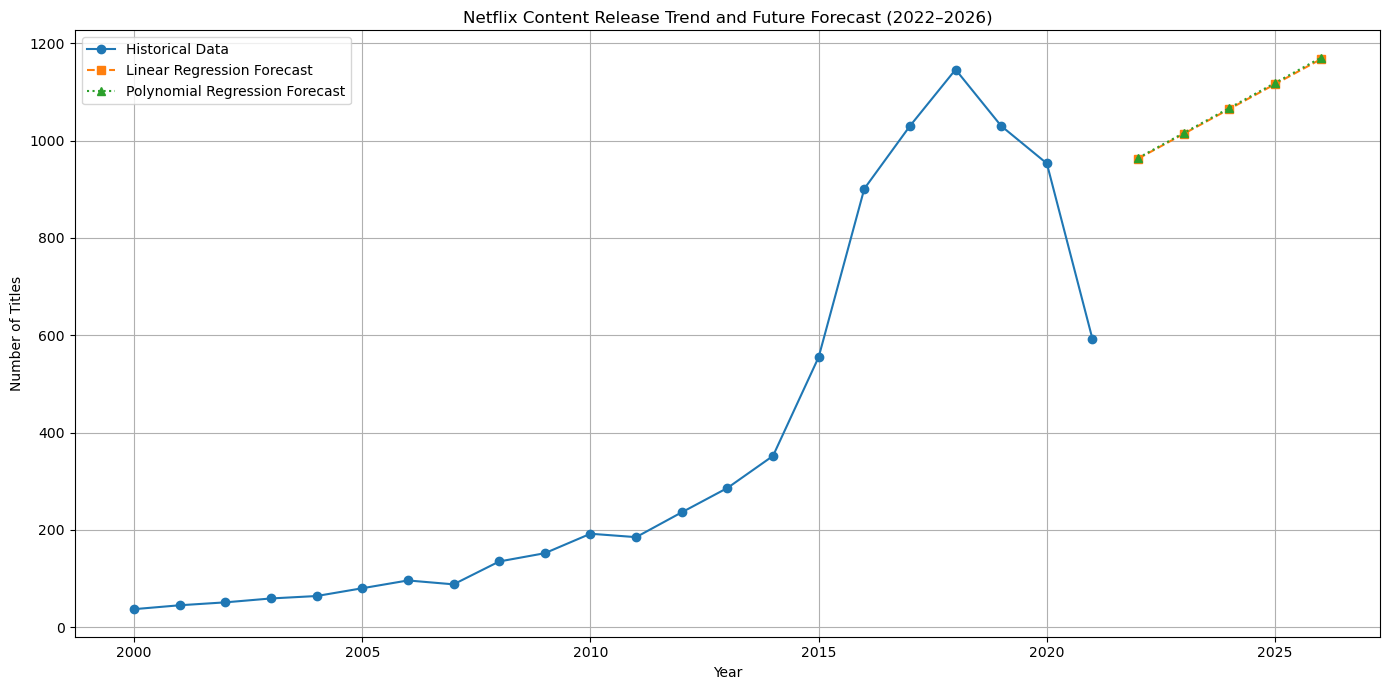

In [21]:
plt.figure(figsize=(14, 7))

# Historical data
plt.plot(
    trend_data['release_year'],
    trend_data['total_titles'],
    marker='o',
    label='Historical Data'
)

# Linear forecast
plt.plot(
    future_years['release_year'],
    linear_forecast,
    marker='s',
    linestyle='--',
    label='Linear Regression Forecast'
)

# Polynomial forecast
plt.plot(
    future_years['release_year'],
    poly_forecast,
    marker='^',
    linestyle=':',
    label='Polynomial Regression Forecast'
)

plt.title('Netflix Content Release Trend and Future Forecast (2022–2026)')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
display(forecast_results)

,Year,Linear Regression,Polynomial Regression
0,2022,963,964
1,2023,1014,1016
2,2024,1065,1067
3,2025,1116,1118
4,2026,1167,1170


### Forecast Interpretation

The forecasting models were used to estimate Netflix content release trends for the period 2022–2026.

Both Linear Regression and Polynomial Regression projected an increasing trend in future title releases. Their predicted values were very close to each other.

Polynomial Regression achieved slightly lower MAE, MSE, and RMSE values than Linear Regression during model evaluation. However, the improvement was marginal.

The historical data showed a significant decline in title releases between 2018 and 2021, which the models did not fully capture.

Therefore, the forecasts should be considered illustrative estimates based on historical patterns rather than actual future release predictions.

### Conclusion

The Netflix Trend Prediction Analysis was successfully completed using Python.

Historical release-year data from 2000 to 2021 was analysed to identify content release patterns and trends.

Two forecasting models, Linear Regression and Polynomial Regression, were developed and evaluated using MAE, MSE, and RMSE.

Polynomial Regression performed marginally better than Linear Regression on the test dataset. Both models were then retrained using the complete historical dataset to forecast trends for 2022–2026.

The project provided practical experience in time series preparation, trend analysis, regression modelling, model evaluation, forecasting, and data visualization.

**Limitations:** The analysis uses a single historical dataset ending in 2021. External factors, changing Netflix strategies, and incomplete historical coverage may affect the reliability of future forecasts.